# Molecular ML : T80 photostability



In [1]:
!pip install -q rdkit gplearn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 52.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.3/40.3 kB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 81.6 MB/s eta 0:00:00


In [2]:
import os, glob
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from rdkit import Chem
from rdkit.Chem import Draw, Descriptors

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge, Lasso, LassoCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import (KFold, RepeatedKFold, LeaveOneOut,
                                     cross_val_score, cross_val_predict)
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import SelectKBest, f_regression
from gplearn.genetic import SymbolicRegressor

SEED = 0
KNOWN3 = ["TDOS4.0", "NumHeteroatoms", "Mass"]
CV = RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEED)

def make_ridge(alpha=1.0):
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=alpha))

def make_rf(max_depth=None, n_estimators=300):
    return make_pipeline(SimpleImputer(strategy="median"),
                         RandomForestRegressor(n_estimators=n_estimators,
                                               max_depth=max_depth, random_state=SEED))

def make_baseline():
    return make_pipeline(SimpleImputer(strategy="median"), DummyRegressor())

def cv_scores(model, X_data, y_data):
    """MSLE of every fold (15 values with RepeatedKFold 5x3)."""
    return -cross_val_score(model, X_data, y_data, cv=CV, scoring="neg_mean_squared_error")

def msle_cv(model, X_data, y_data):
    s = cv_scores(model, X_data, y_data)
    return s.mean(), s.std()

def loo_msle(model, X_data, y_data):
    p = cross_val_predict(model, X_data, y_data, cv=LeaveOneOut())
    return np.mean((p - y_data) ** 2)

## Section 1 : Load and inspect the data

Read the competition's training and test files. Check the number of rows and columns, column names, missing values, and the distribution of T80.

**Output:** a clear understanding of what the dataset contains.

In [3]:
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

train = pd.read_csv(glob.glob("/kaggle/input/**/train.csv", recursive=True)[0])
test  = pd.read_csv(glob.glob("/kaggle/input/**/test.csv",  recursive=True)[0])
sample_path = glob.glob("/kaggle/input/**/sample_submission.csv", recursive=True)[0]

print("\nTrain shape:", train.shape)
print("Test shape: ", test.shape)
print(list(train.columns))

print("Only in train:", set(train.columns) - set(test.columns))

print("\nFirst five training rows:")
display(train.head())

print("Total missing values  train:", int(train.isnull().sum().sum()),
      "| test:", int(test.isnull().sum().sum()))

/kaggle/input/competitions/molecular-machine-learning/sample_submission.csv
/kaggle/input/competitions/molecular-machine-learning/train.csv
/kaggle/input/competitions/molecular-machine-learning/test.csv

Train shape: (42, 146)
Test shape:  (9, 146)
['Batch_ID', 'T80', 'Smiles', 'Mass', 'HAcceptors', 'HDonors', 'LogP', 'Asphericity', 'Rg', 'TPSA', 'RingCount', 'NumRotatableBonds', 'NumHeteroatoms', 'HOMOm1(eV)', 'HOMO(eV)', 'LUMO(eV)', 'LUMOp1(eV)', 'PrimeState', 'PrimeExcite(eV)', 'PrimeExcite(osc)', 'DipoleMoment(Debye)', 'SurfaceCharge', 'ChargeCorrection', 'T1', 'T2', 'T3', 'T4', 'T5', 'T6', 'T7', 'T8', 'T9', 'T10', 'T11', 'T12', 'T13', 'T14', 'T15', 'T16', 'T17', 'T18', 'T19', 'T20', 'S1', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9', 'S10', 'S11', 'S12', 'S13', 'S14', 'S15', 'S16', 'S17', 'S18', 'S19', 'S20', 'O1', 'O2', 'O3', 'O4', 'O5', 'O6', 'O7', 'O8', 'O9', 'O10', 'O11', 'O12', 'O13', 'O14', 'O15', 'O16', 'O17', 'O18', 'O19', 'O20', 'TDOS1.5', 'TDOS1.6', 'TDOS1.7', 'TDOS1.8

,Batch_ID,T80,Smiles,Mass,HAcceptors,HDonors,LogP,Asphericity,Rg,TPSA,...,SDOS4.5,SDOS4.6,SDOS4.7,SDOS4.8,SDOS4.9,SDOS5.0,SDOS5.1,SDOS5.2,SDOS5.3,SDOS5.4
0,Train-01,103.86,CCCCCCCCCCCCc1ccsc1-c1ccc(-c2cccs2)cc1,410.692,2,0,9.6070,0.301361,5.187321,0.00,...,1.717761,1.970186,1.760071,1.224983,0.664733,0.282353,0.096763,0.034589,0.030793,0.057340
1,Train-02,101.13,CCCCCCCCCCCCc1ccsc1-c1cccs1,334.594,2,0,7.9400,0.367472,4.141425,0.00,...,0.012396,0.046031,0.133124,0.299840,0.525958,0.718549,0.764711,0.634854,0.414866,0.225909
2,Train-03,78.30,CN1CCN(S(=O)(=O)c2ccc(-c3ccc(-c4cccs4)cc3)cc2)CC1,398.553,4,0,4.0182,0.799589,5.368024,40.62,...,2.421162,2.703267,2.352276,1.595867,0.845839,0.354620,0.127878,0.060600,0.064782,0.098908
3,Train-04,71.88,O=C1c2ccccc2C(=O)c2cc(-c3ccc(-c4cccs4)s3)ccc21,372.470,4,0,5.9190,0.793825,4.948903,34.14,...,0.886320,0.579059,0.345148,0.246564,0.276259,0.381997,0.495304,0.566935,0.594203,0.614075
4,Train-05,68.37,CC(C)(C)OC(=O)n1ccc2ccc(-c3ccc(-c4ccc(-c5cccs5...,457.620,5,0,8.5485,0.671148,5.994751,31.23,...,0.487723,0.245764,0.249019,0.363222,0.474953,0.505358,0.440671,0.330129,0.234649,0.183111


Total missing values  train: 0 | test: 9


count     42.000000
mean      22.710476
std       26.896407
min        1.500000
25%        5.085000
50%       10.485000
75%       30.182500
max      103.860000
Name: T80, dtype: float64


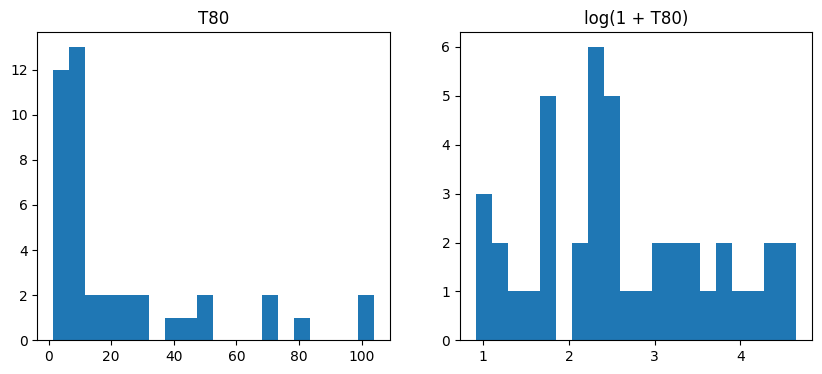

In [4]:
print(train["T80"].describe())

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].hist(train["T80"], bins=20)
ax[0].set_title("T80")
ax[1].hist(np.log1p(train["T80"]), bins=20)
ax[1].set_title("log(1 + T80)")
plt.show()

## Section 2 : Explore the chemistry

Inspect the SMILES strings and visualize a few molecules using RDKit. Look at molecular mass, heteroatom count, and the provided features.

**Output:** a basic chemical understanding of the molecules.

Failed to parse: 0


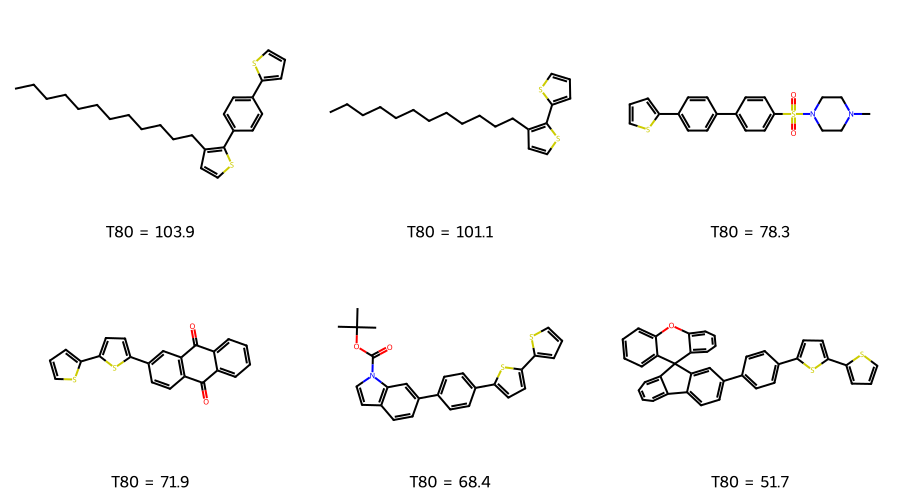

In [5]:
mols = [Chem.MolFromSmiles(s) for s in train["Smiles"]]
print("Failed to parse:", sum(m is None for m in mols))

display(Draw.MolsToGridImage(
    mols[:6],
    molsPerRow=3,
    subImgSize=(300, 250),
    legends=[f"T80 = {t:.1f}" for t in train["T80"].iloc[:6]],
))

In [6]:
def count_heteroatoms(mol):
    return sum(1 for a in mol.GetAtoms() if a.GetAtomicNum() not in (1, 6))

chem_check = pd.DataFrame({
    "Mass":           train["Mass"],
    "rdkit_mass":     [Descriptors.MolWt(m) for m in mols],
    "NumHeteroatoms": train["NumHeteroatoms"],
    "rdkit_hetero":   [count_heteroatoms(m) for m in mols],
})
print(chem_check.head(10))
print("Mass matches RDKit:        ", np.allclose(chem_check["Mass"], chem_check["rdkit_mass"], atol=1e-3))
print("Heteroatoms match RDKit:   ", (chem_check["NumHeteroatoms"] == chem_check["rdkit_hetero"]).all())

      Mass  rdkit_mass  NumHeteroatoms  rdkit_hetero
0  410.692     410.692               2             2
1  334.594     334.594               2             2
2  398.553     398.553               6             6
3  372.470     372.470               4             4
4  457.620     457.620               5             5
5  572.754     572.754               3             3
6  425.575     425.575               6             6
7  374.494     374.494               6             6
8  580.975     580.975               5             5
9  522.735     522.735               4             4
Mass matches RDKit:         True
Heteroatoms match RDKit:    True


## Section 3 : Explore the target and features

Plot T80 against a few features. Check whether higher molecular mass, more heteroatoms, or TDOS4.0 appear related to photostability.

**Output:** a few graphs and initial hypotheses.

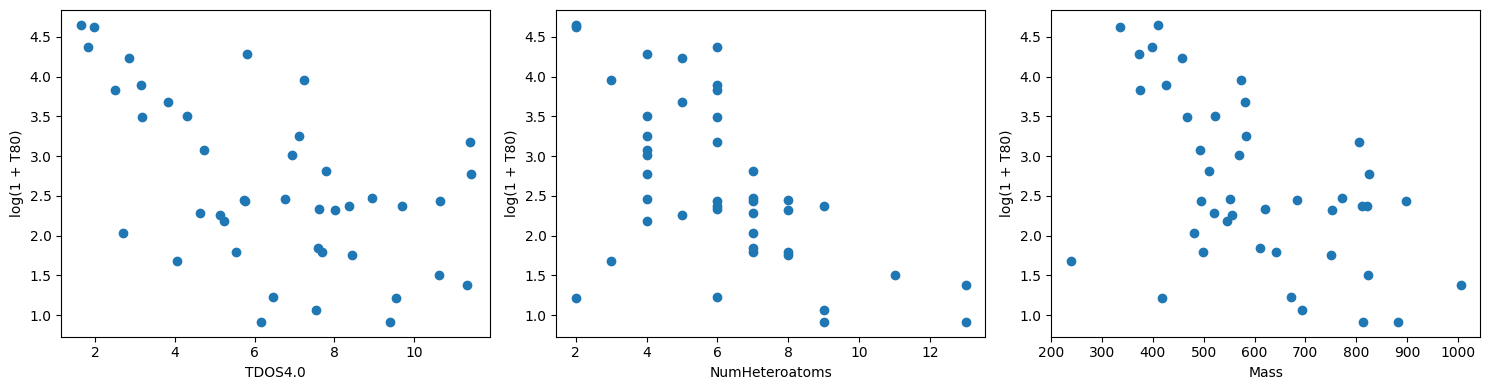

NumHeteroatoms    0.585401
HAcceptors        0.574648
TDOS3.9           0.573560
TDOS4.0           0.556002
S15               0.536258
S12               0.534590
S17               0.534455
S16               0.531641
S14               0.529947
S13               0.528159
Name: logT80, dtype: float64


In [7]:
train["logT80"] = np.log1p(train["T80"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, f in zip(axes, KNOWN3):
    ax.scatter(train[f], train["logT80"])
    ax.set_xlabel(f)
    ax.set_ylabel("log(1 + T80)")
plt.tight_layout()
plt.show()

corr = train.corr(numeric_only=True)["logT80"].drop(["logT80", "T80"])
print(corr.abs().sort_values(ascending=False).head(10))

## Section 4 : Build a baseline model

Start with a simple model (Ridge), then compare it with a random forest.

**Output:** your first predictions and a baseline score.

In [8]:
drop_cols = ["Batch_ID", "Smiles", "T80", "logT80"]
feature_cols = [c for c in train.columns
                if c not in drop_cols and pd.api.types.is_numeric_dtype(train[c])]
print(len(feature_cols), "features")

X  = train[feature_cols]
X3 = train[KNOWN3]
y  = train["logT80"]

ridge = make_ridge(alpha=10).fit(X, y)
rf    = make_rf().fit(X, y)

for name, model in [("ridge", ridge), ("rf", rf)]:
    pred = model.predict(X)
    print(f"{name:6s} train RMSLE: {np.sqrt(np.mean((pred - y) ** 2)):.4f}")

143 features
ridge  train RMSLE: 0.3360
rf     train RMSLE: 0.3408


## Section 5 : Validate and improve

Use repeated 5-fold cross-validation (5 folds x 3 repeats) and compare models with the competition's metric, MSLE. The same CV scheme is used for all model-selection decisions in this notebook.

**Output:** a fair comparison of models on unseen training examples.

                       MSLE    Std  RMSLE  Improvement vs baseline (%)
ridge a=1 (3 feats)   0.647  0.225  0.804                       42.895
rf depth 4 (3 feats)  0.746  0.309  0.864                       34.153
rf (all)              0.821  0.313  0.906                       27.484
rf depth 4 (all)      0.829  0.312  0.910                       26.809
ridge a=100 (all)     0.863  0.392  0.929                       23.826
mean baseline         1.133  0.315  1.064                        0.000
ridge a=10 (all)      1.767  1.619  1.329                      -55.988
ridge a=1 (all)       3.578  4.313  1.892                     -215.930


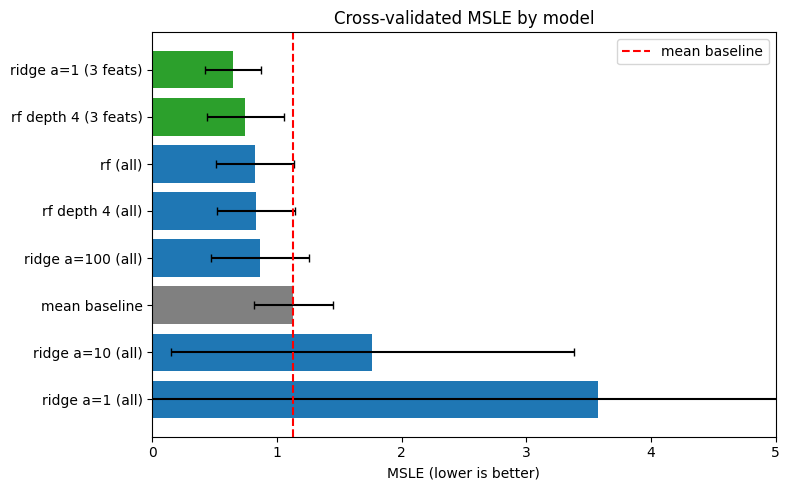

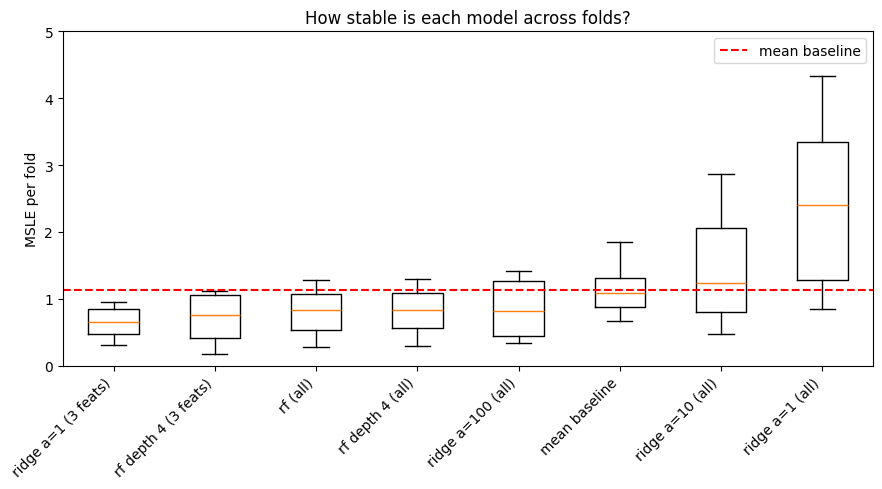

In [9]:
fold_scores = {}

all_feature_models = {
    "mean baseline": make_baseline(),
    "ridge a=1":     make_ridge(1),
    "ridge a=10":    make_ridge(10),
    "ridge a=100":   make_ridge(100),
    "rf":            make_rf(),
    "rf depth 4":    make_rf(max_depth=4),
}
for name, m in all_feature_models.items():
    label = name if name == "mean baseline" else f"{name} (all)"
    fold_scores[label] = cv_scores(m, X, y)

fold_scores["ridge a=1 (3 feats)"]   = cv_scores(make_ridge(1), X3, y)
fold_scores["rf depth 4 (3 feats)"]  = cv_scores(make_rf(max_depth=4), X3, y)

table = pd.DataFrame({
    "MSLE": {k: v.mean() for k, v in fold_scores.items()},
    "Std":  {k: v.std()  for k, v in fold_scores.items()},
})
table["RMSLE"] = np.sqrt(table["MSLE"])
base = table.loc["mean baseline", "MSLE"]
table["Improvement vs baseline (%)"] = (1 - table["MSLE"] / base) * 100
table = table.sort_values("MSLE")
print(table.round(3))

colors = ["gray" if n == "mean baseline"
          else "tab:green" if "3 feats" in n
          else "tab:blue" for n in table.index]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(table.index, table["MSLE"], xerr=table["Std"], color=colors, capsize=3)
ax.axvline(base, color="red", linestyle="--", label="mean baseline")
ax.set_xlim(0, 5)
ax.set_xlabel("MSLE (lower is better)")
ax.set_title("Cross-validated MSLE by model")
ax.invert_yaxis()
ax.legend()
plt.tight_layout()
plt.show()

order = list(table.index)
fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot([fold_scores[n] for n in order], tick_labels=order, vert=True)
ax.axhline(base, color="red", linestyle="--", label="mean baseline")
ax.set_ylim(0, 5)
ax.set_ylabel("MSLE per fold")
ax.set_title("How stable is each model across folds?")
plt.xticks(rotation=45, ha="right")
ax.legend()
plt.tight_layout()
plt.show()

## Section 6 : Identify important molecular features

Examine which features the models use. Check whether the competition's known candidates — TDOS4.0, NumHeteroatoms, and Mass — are useful.

**Output:** a small, interpretable set of potentially important features.

### 6A : Random forest importance

TDOS3.9                0.104
TDOS3.8                0.075
Mass                   0.058
TDOS4.0                0.050
TDOS2.9                0.044
NumHeteroatoms         0.038
DipoleMoment(Debye)    0.036
S3                     0.034
TDOS3.0                0.028
LUMO(eV)               0.024
HOMOm1(eV)             0.021
S5                     0.021
SDOS4.0                0.020
TDOS4.1                0.019
S2                     0.019
dtype: float64


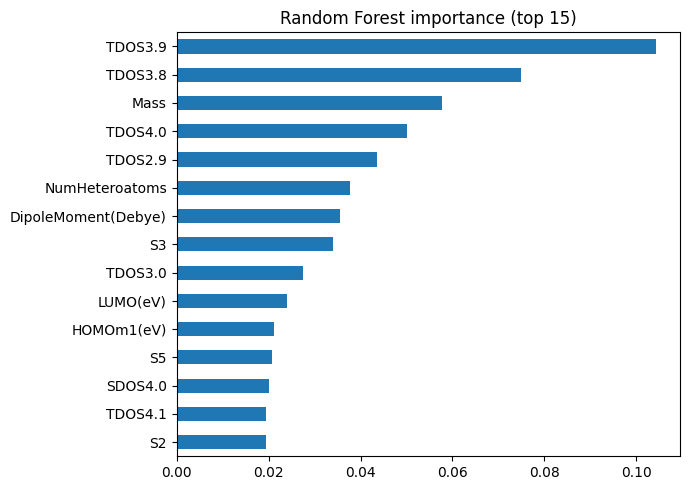

TDOS4.0          RF rank: 4 of 143
NumHeteroatoms   RF rank: 6 of 143
Mass             RF rank: 3 of 143


In [10]:
rf_best = make_rf(max_depth=4, n_estimators=500).fit(X, y)

rf_imp = pd.Series(rf_best[-1].feature_importances_, index=X.columns).sort_values(ascending=False)
print(rf_imp.head(15).round(3))

rf_imp.head(15)[::-1].plot(kind="barh", figsize=(7, 5), title="Random Forest importance (top 15)")
plt.tight_layout(); plt.show()

for f in KNOWN3:
    print(f"{f:16s} RF rank: {rf_imp.index.get_loc(f) + 1} of {len(rf_imp)}")

### 6B : Permutation importance on held-out molecules

In [11]:
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
perm_all = []

for tr_idx, va_idx in kf.split(X):
    m = make_rf(max_depth=4).fit(X.iloc[tr_idx], y.iloc[tr_idx])
    r = permutation_importance(m, X.iloc[va_idx], y.iloc[va_idx],
                               n_repeats=10, random_state=SEED,
                               scoring="neg_mean_squared_error")
    perm_all.append(r.importances_mean)

perm_imp = pd.Series(np.mean(perm_all, axis=0), index=X.columns).sort_values(ascending=False)
print(perm_imp.head(15).round(4))

for f in KNOWN3:
    print(f"{f:16s} permutation rank: {perm_imp.index.get_loc(f) + 1} of {len(perm_imp)}")

TDOS4.0           0.0340
TDOS3.9           0.0302
Mass              0.0258
TDOS2.9           0.0218
NumHeteroatoms    0.0182
TDOS3.0           0.0119
TDOS4.1           0.0111
HAcceptors        0.0109
TPSA              0.0082
S5                0.0077
SDOS4.0           0.0077
O2                0.0052
LUMO(eV)          0.0051
TDOS3.3           0.0049
TDOS3.2           0.0047
dtype: float64
TDOS4.0          permutation rank: 1 of 143
NumHeteroatoms   permutation rank: 5 of 143
Mass             permutation rank: 3 of 143


### 6C : Lasso and bootstrap stability

In [12]:
Xs = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(X))

lasso_cv = LassoCV(cv=KFold(5, shuffle=True, random_state=SEED),
                   random_state=SEED, max_iter=50000).fit(Xs, y)
print("chosen alpha:", lasso_cv.alpha_)
coefs = pd.Series(lasso_cv.coef_, index=X.columns)
print("Non-zero coefficients:\n", coefs[coefs != 0].sort_values(key=abs, ascending=False).round(3))

counts = pd.Series(0, index=X.columns, dtype=float)
n_boot = 100
for seed in range(n_boot):
    idx = np.random.default_rng(seed).choice(len(y), size=len(y), replace=True)
    l = Lasso(alpha=lasso_cv.alpha_, max_iter=50000).fit(Xs[idx], y.iloc[idx])
    counts += (l.coef_ != 0)

lasso_freq = (counts / n_boot).sort_values(ascending=False)
print(lasso_freq.head(15).round(2))

chosen alpha: 0.13060538843658143
Non-zero coefficients:
 NumHeteroatoms      -0.308
TDOS4.0             -0.292
T1                   0.162
TDOS4.6              0.103
TDOS3.3              0.097
O14                 -0.084
TDOS2.8             -0.020
O10                  0.019
HDonors             -0.017
NumRotatableBonds   -0.012
dtype: float64
NumHeteroatoms       0.64
O10                  0.48
NumRotatableBonds    0.46
TDOS4.0              0.45
O14                  0.40
T1                   0.39
HDonors              0.35
TDOS3.3              0.32
TDOS3.9              0.30
TDOS4.5              0.28
TDOS3.2              0.28
TDOS4.6              0.27
O18                  0.23
HAcceptors           0.22
O11                  0.22
dtype: float64


### 6D : Combine the three rankings

In [13]:
ranks = pd.DataFrame({
    "RF":          rf_imp.rank(ascending=False),
    "Permutation": perm_imp.rank(ascending=False),
    "Lasso freq":  lasso_freq.rank(ascending=False),
})
ranks["avg_rank"] = ranks.mean(axis=1)
ranks = ranks.sort_values("avg_rank")

print(ranks.head(15).round(1))
print("\nThe three known features:")
print(ranks.loc[KNOWN3].round(1))

                     RF  Permutation  Lasso freq  avg_rank
TDOS4.0             4.0          1.0         4.0       3.0
NumHeteroatoms      6.0          5.0         1.0       4.0
TDOS3.9             1.0          2.0         9.0       4.0
TDOS2.9             5.0          4.0        20.5       9.8
Mass                3.0          3.0        29.5      11.8
HAcceptors         16.0          8.0        14.5      12.8
TDOS3.3            20.0         14.0         8.0      14.0
NumRotatableBonds  29.0         16.0         3.0      16.0
TDOS3.2            27.0         15.0        10.5      17.5
LUMO(eV)           10.0         13.0        32.5      18.5
TPSA               26.0          9.0        32.5      22.5
HOMOm1(eV)         11.0         50.0        17.0      26.0
SDOS4.0            13.0         11.0        55.0      26.3
TDOS4.1            14.0          7.0        60.0      27.0
TDOS4.6            38.0         31.0        12.0      27.0

The three known features:
                 RF  Permutat

### 6E : Test small feature sets honestly

TDOS4.0 + NumHeteroatoms + Mass    0.647
TDOS4.0 + NumHeteroatoms           0.655
NumHeteroatoms + Mass              0.751
NumHeteroatoms                     0.764
TDOS4.0                            0.827
TDOS4.0 + Mass                     0.841
Mass                               0.852
dtype: float64


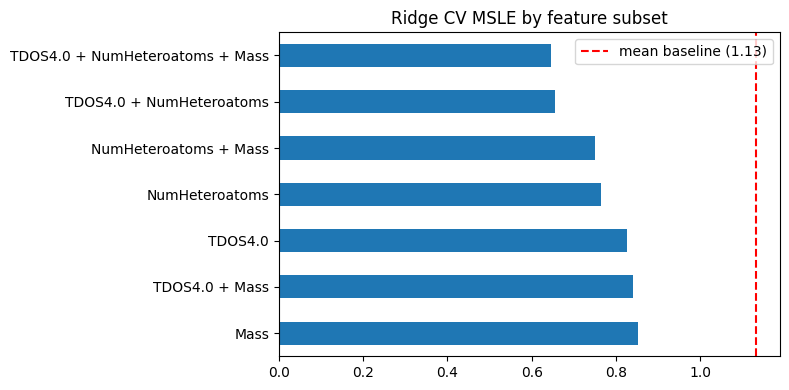

In [14]:
subset_scores = {}
for r in (1, 2, 3):
    for combo in combinations(KNOWN3, r):
        subset_scores[" + ".join(combo)] = msle_cv(make_ridge(1), train[list(combo)], y)[0]
subset_scores = pd.Series(subset_scores).sort_values()
print(subset_scores.round(3))

subset_scores[::-1].plot(kind="barh", figsize=(8, 4), title="Ridge CV MSLE by feature subset")
plt.axvline(base, color="red", linestyle="--", label=f"mean baseline ({base:.2f})")
plt.legend(); plt.tight_layout(); plt.show()

In [15]:
ALPHAS = [0.01, 0.1, 1, 3, 10, 30, 100]
alpha_scores = pd.Series({a: msle_cv(make_ridge(a), X3, y)[0] for a in ALPHAS})
print(alpha_scores.round(3))
best_alpha = alpha_scores.idxmin()
print("best alpha:", best_alpha)

0.01      0.650
0.10      0.649
1.00      0.647
3.00      0.652
10.00     0.672
30.00     0.713
100.00    0.827
dtype: float64
best alpha: 1.0


In [16]:
for k in [1, 2, 3, 5, 10, 20]:
    m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                      SelectKBest(f_regression, k=k), Ridge(alpha=10))
    print(f"top {k:2d} chosen automatically inside CV: MSLE = {msle_cv(m, X, y)[0]:.3f}")

top  1 chosen automatically inside CV: MSLE = 1.065
top  2 chosen automatically inside CV: MSLE = 1.086
top  3 chosen automatically inside CV: MSLE = 1.068
top  5 chosen automatically inside CV: MSLE = 0.988
top 10 chosen automatically inside CV: MSLE = 0.929
top 20 chosen automatically inside CV: MSLE = 0.928


### 6F : Brute-force small subsets

**Caution:** the shortlist is ranked on the full training set and ~575 subsets are then scored on only 42 molecules, so the best score here is optimistically biased. Treat these subsets as hypotheses, not as proven improvements over the three known features.

In [17]:
shortlist = list(ranks.head(15).index)
results = []
for r in (1, 2, 3):
    for combo in combinations(shortlist, r):
        results.append((msle_cv(make_ridge(1), train[list(combo)], y)[0], combo))

for score, combo in sorted(results)[:10]:
    print(round(score, 3), combo)

0.603 ('TDOS4.0', 'NumHeteroatoms', 'TDOS3.2')
0.604 ('NumHeteroatoms', 'TDOS3.9', 'TDOS3.2')
0.606 ('TDOS4.0', 'NumHeteroatoms', 'TDOS3.3')
0.611 ('NumHeteroatoms', 'TDOS3.9', 'TDOS3.3')
0.618 ('TDOS4.0', 'NumHeteroatoms', 'TDOS4.6')
0.623 ('NumHeteroatoms', 'TDOS4.1', 'TDOS4.6')
0.635 ('TDOS3.9', 'HAcceptors', 'TDOS3.2')
0.641 ('TDOS4.0', 'HAcceptors', 'TDOS3.2')
0.645 ('TDOS3.9', 'HAcceptors', 'TDOS3.3')
0.646 ('TDOS4.0', 'HAcceptors', 'TDOS3.3')


## Section 7 : Generate the submission

Train the chosen model (Ridge + random forest blend on the three known features) on all labeled molecules, predict T80 for the test molecules, and save the predictions in the required CSV format. The three known features are used instead of the Section 6F winners because those were selected from many candidates on 42 molecules and are likely overfitted.

**Output:** `submission.csv` containing ID and T80.

### 7A : Check the test features are inside the training range

In [18]:
check = pd.DataFrame({
    "train_min": train[KNOWN3].min(),
    "train_max": train[KNOWN3].max(),
    "test_min":  test[KNOWN3].min(),
    "test_max":  test[KNOWN3].max(),
    "test_missing": test[KNOWN3].isna().sum(),
})
print(check.round(2))

for f in KNOWN3:
    outside = ((test[f] < train[f].min()) | (test[f] > train[f].max())).sum()
    print(f"{f}: {outside} test molecules outside the training range")

                train_min  train_max  test_min  test_max  test_missing
TDOS4.0              1.63      11.42      2.28      5.12             0
NumHeteroatoms       2.00      13.00      2.00      5.00             0
Mass               238.32    1005.43    238.32    500.88             0
TDOS4.0: 0 test molecules outside the training range
NumHeteroatoms: 0 test molecules outside the training range
Mass: 0 test molecules outside the training range


### 7B : Validate the blend (leave-one-out) before using it

In [19]:
W_RIDGE = 0.7

p_ridge = cross_val_predict(make_ridge(best_alpha),     X3, y, cv=LeaveOneOut())
p_rf    = cross_val_predict(make_rf(max_depth=4),       X3, y, cv=LeaveOneOut())
p_blend = W_RIDGE * p_ridge + (1 - W_RIDGE) * p_rf

print("mean baseline      :", round(loo_msle(make_baseline(), X3, y), 3))
for name, p in [("ridge", p_ridge), ("rf", p_rf), (f"blend {W_RIDGE:.0%}/{1-W_RIDGE:.0%}", p_blend)]:
    print(f"{name:18s} LOO MSLE: {np.mean((p - y) ** 2):.3f}")

mean baseline      : 1.125
ridge              LOO MSLE: 0.685
rf                 LOO MSLE: 0.828
blend 70%/30%      LOO MSLE: 0.680


### 7C : Fit the final models

In [20]:
final_ridge = make_ridge(best_alpha).fit(X3, y)
final_rf    = make_rf(max_depth=4).fit(X3, y)

coef = pd.Series(final_ridge[-1].coef_, index=KNOWN3)
print(coef.round(3))

TDOS4.0          -0.566
NumHeteroatoms   -0.569
Mass              0.277
dtype: float64


### 7D : Predict and compare the models

In [21]:
pred_ridge_log = final_ridge.predict(test[KNOWN3])
pred_rf_log    = final_rf.predict(test[KNOWN3])
pred_blend_log = W_RIDGE * pred_ridge_log + (1 - W_RIDGE) * pred_rf_log

compare = pd.DataFrame({
    "Batch_ID":  test["Batch_ID"],
    "ridge_T80": np.expm1(pred_ridge_log),
    "rf_T80":    np.expm1(pred_rf_log),
    "blend_T80": np.expm1(pred_blend_log),
})
print(compare.round(2))
print("Training T80 range:", train["T80"].min(), "to", train["T80"].max())

  Batch_ID  ridge_T80  rf_T80  blend_T80
0  Test-01      30.59   51.87      35.87
1  Test-02      30.60   31.63      30.91
2  Test-03      17.84   25.32      19.82
3  Test-04      28.41   22.34      26.43
4  Test-05      41.74   30.39      37.96
5  Test-06      37.64   33.66      36.40
6  Test-07      24.15   55.66      31.09
7  Test-08      24.62   12.55      20.16
8  Test-09      25.70   17.02      22.73
Training T80 range: 1.5 to 103.86


### 7E : Build and verify the file

In [22]:
pred_t80 = np.clip(np.expm1(pred_blend_log), 0, None)

sample = pd.read_csv(sample_path)
print(sample.head())
id_col = sample.columns[0]

pred_by_id = pd.Series(pred_t80, index=test["Batch_ID"].values)
assert set(sample[id_col]) == set(pred_by_id.index), "IDs differ between sample and test"

sample["T80"] = pred_by_id.reindex(sample[id_col]).values
assert sample["T80"].notna().all() and (sample["T80"] >= 0).all()
sample.to_csv("submission.csv", index=False)
print("Saved:", sample.shape)
print(pd.read_csv("submission.csv"))

  Batch_ID  T80
0  Test-01  1.5
1  Test-02  2.5
2  Test-03  3.5
3  Test-04  4.5
4  Test-05  5.5
Saved: (9, 2)
  Batch_ID        T80
0  Test-01  35.870911
1  Test-02  30.906185
2  Test-03  19.824004
3  Test-04  26.434628
4  Test-05  37.960831
5  Test-06  36.399691
6  Test-07  31.090904
7  Test-08  20.164792
8  Test-09  22.729838


### 7F : Plot where the predictions fall

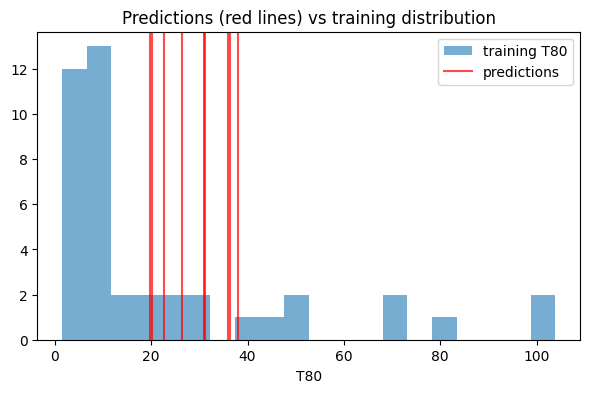

In [23]:
plt.figure(figsize=(7, 4))
plt.hist(train["T80"], bins=20, alpha=0.6, label="training T80")
for i, p in enumerate(pred_t80):
    plt.axvline(p, color="red", alpha=0.7, label="predictions" if i == 0 else None)
plt.xlabel("T80"); plt.title("Predictions (red lines) vs training distribution")
plt.legend(); plt.show()

## Section 8 : Symbolic regression (exploratory, not used in the submission)

Compare a genetic-programming formula against Ridge using the same CV scheme and the same three features.

In [24]:
SR_FEATS = KNOWN3

sr_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    SymbolicRegressor(population_size=1000, generations=15,
                      function_set=("add", "sub", "mul", "div"),
                      parsimony_coefficient=0.05,
                      random_state=SEED, n_jobs=1)
)

sr_mean, sr_sd       = msle_cv(sr_model, train[SR_FEATS], y)
ridge_mean, ridge_sd = msle_cv(make_ridge(best_alpha), X3, y)
print(f"Symbolic regression CV MSLE: {sr_mean:.3f} (+/- {sr_sd:.3f})")
print(f"Ridge (3 features) CV MSLE:  {ridge_mean:.3f} (+/- {ridge_sd:.3f})")
print(f"Mean baseline CV MSLE:       {base:.3f}")

sr_model.fit(train[SR_FEATS], y)
print(sr_model[-1]._program)

Symbolic regression CV MSLE: 1.252 (+/- 0.369)
Ridge (3 features) CV MSLE:  0.647 (+/- 0.225)
Mean baseline CV MSLE:       1.133
add(sub(0.900, X1), sub(0.900, -0.854))
